# Linear and Logistic Regression — From Scratch

This project explores two supervised learning tasks and compares custom gradient-descent implementations with Scikit-learn:

1. **Linear Regression:** predict a continuous target using synthetic data. Compare Batch Gradient Descent (BGD), Stochastic Gradient Descent (SGD), and Mini-Batch Gradient Descent (MBGD).
2. **Logistic Regression:** classify breast-cancer samples as malignant or benign using the Breast Cancer Wisconsin dataset. Implement batch, stochastic, and mini-batch gradient descent and compare with Scikit-learn.

The custom models use NumPy for the core optimization algorithms.

## 1. Imports and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error,
    accuracy_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Part A — Linear Regression

## 2. Generate synthetic data

The target follows approximately `y = 4x - 2` with additive Gaussian noise.

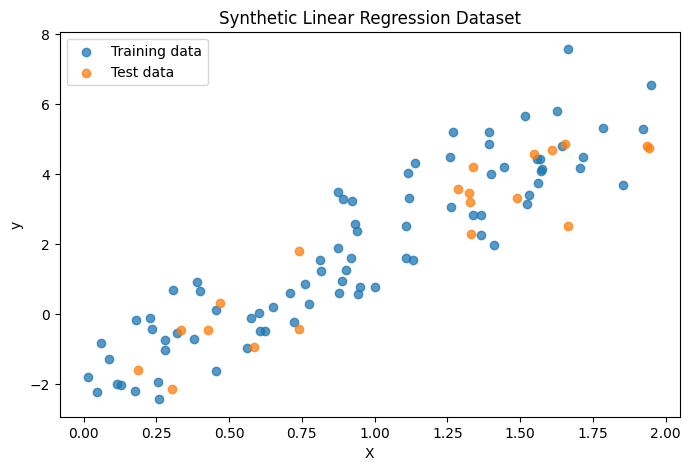

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
X = 2 * rng.random((100, 1))
noise = rng.normal(0, 1, (100, 1))
y = 4 * X - 2 + noise

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data", alpha=0.75)
plt.scatter(X_test, y_test, label="Test data", alpha=0.75)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Synthetic Linear Regression Dataset")
plt.legend()
plt.show()

## 3. Linear Regression with Batch Gradient Descent

For mean squared error, the gradient is calculated over the complete training set at each update.

In [3]:
def add_bias(X):
    X = np.asarray(X, dtype=float)
    return np.c_[np.ones((X.shape[0], 1)), X]


def linear_batch_gd(X, y, learning_rate=0.05, epochs=1000, random_state=42):
    X_b = add_bias(X)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    rng = np.random.default_rng(random_state)
    theta = rng.normal(size=(X_b.shape[1], 1))
    losses = []

    for _ in range(epochs):
        errors = X_b @ theta - y
        gradients = (2 / len(y)) * (X_b.T @ errors)
        theta -= learning_rate * gradients
        losses.append(float(np.mean((X_b @ theta - y) ** 2)))

    return theta, losses

## 4. Linear Regression with Stochastic Gradient Descent

SGD updates the parameters using one randomly selected training example at a time.

In [4]:
def linear_sgd(X, y, learning_rate=0.01, epochs=100, random_state=42):
    X_b = add_bias(X)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    rng = np.random.default_rng(random_state)
    theta = rng.normal(size=(X_b.shape[1], 1))
    losses = []

    for _ in range(epochs):
        for idx in rng.permutation(len(y)):
            xi = X_b[idx:idx+1]
            yi = y[idx:idx+1]
            gradient = 2 * xi.T @ (xi @ theta - yi)
            theta -= learning_rate * gradient

        losses.append(float(np.mean((X_b @ theta - y) ** 2)))

    return theta, losses

## 5. Linear Regression with Mini-Batch Gradient Descent

Mini-batch gradient descent updates the parameters using small batches. The gradient is divided by the actual batch length, including the final batch when it is smaller than the selected batch size.

In [5]:
def linear_mini_batch_gd(
    X, y, learning_rate=0.03, epochs=300, batch_size=10, random_state=42
):
    X_b = add_bias(X)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    rng = np.random.default_rng(random_state)
    theta = rng.normal(size=(X_b.shape[1], 1))
    losses = []

    for _ in range(epochs):
        indices = rng.permutation(len(y))
        X_shuffled, y_shuffled = X_b[indices], y[indices]

        for start in range(0, len(y), batch_size):
            X_batch = X_shuffled[start:start+batch_size]
            y_batch = y_shuffled[start:start+batch_size]
            batch_length = len(y_batch)

            gradients = (2 / batch_length) * X_batch.T @ (
                X_batch @ theta - y_batch
            )
            theta -= learning_rate * gradients

        losses.append(float(np.mean((X_b @ theta - y) ** 2)))

    return theta, losses

## 6. Train and evaluate the linear models

All custom methods are evaluated on the same held-out test set. Scikit-learn Linear Regression is included as a reference baseline.

In [6]:
theta_bgd, loss_bgd = linear_batch_gd(X_train, y_train)
theta_sgd, loss_sgd = linear_sgd(X_train, y_train)
theta_mbgd, loss_mbgd = linear_mini_batch_gd(X_train, y_train)

def linear_predict(theta, X):
    return add_bias(X) @ theta

linear_models = {
    "Batch GD": theta_bgd,
    "Stochastic GD": theta_sgd,
    "Mini-Batch GD": theta_mbgd
}

linear_results = []
for name, theta in linear_models.items():
    predictions = linear_predict(theta, X_test)
    linear_results.append({
        "Model": name,
        "Test MSE": mean_squared_error(y_test, predictions),
        "Intercept": float(theta[0, 0]),
        "Coefficient": float(theta[1, 0])
    })

sk_linear = LinearRegression()
sk_linear.fit(X_train, y_train)
sk_predictions = sk_linear.predict(X_test)
linear_results.append({
    "Model": "Scikit-learn",
    "Test MSE": mean_squared_error(y_test, sk_predictions),
    "Intercept": float(sk_linear.intercept_[0]),
    "Coefficient": float(sk_linear.coef_[0, 0])
})

linear_results_df = pd.DataFrame(linear_results).sort_values("Test MSE")
display(linear_results_df.round(4))

,Model,Test MSE,Intercept,Coefficient
1,Stochastic GD,0.7825,-2.0992,4.0792
0,Batch GD,0.8587,-2.0511,4.1232
3,Scikit-learn,0.8587,-2.0511,4.1232
2,Mini-Batch GD,0.8599,-2.0490,4.1225


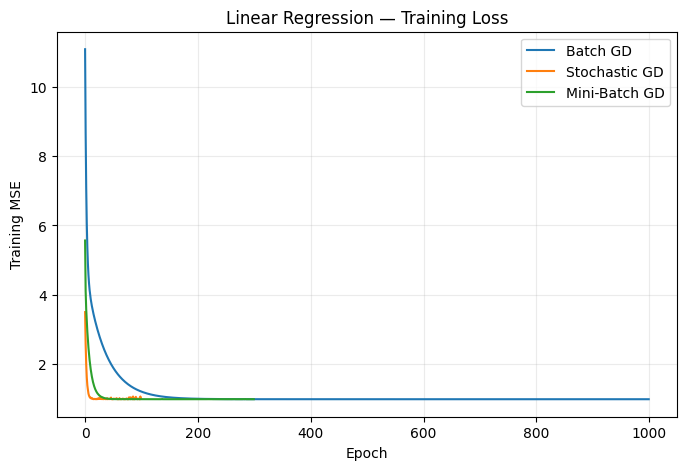

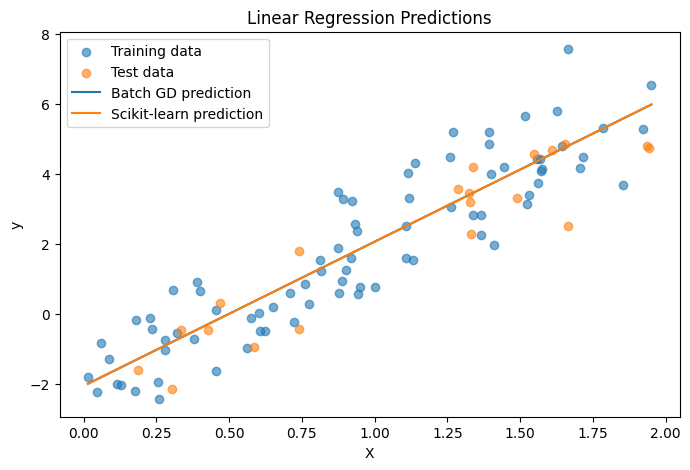

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(loss_bgd, label="Batch GD")
plt.plot(loss_sgd, label="Stochastic GD")
plt.plot(loss_mbgd, label="Mini-Batch GD")
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Linear Regression — Training Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data", alpha=0.6)
plt.scatter(X_test, y_test, label="Test data", alpha=0.6)
plt.plot(x_line, linear_predict(theta_bgd, x_line), label="Batch GD prediction")
plt.plot(x_line, sk_linear.predict(x_line), label="Scikit-learn prediction")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression Predictions")
plt.legend()
plt.show()

# Part B — Logistic Regression

## 7. Load the Breast Cancer Wisconsin dataset

The target classes are encoded by Scikit-learn as:
- `0`: malignant
- `1`: benign

The dataset contains 30 numeric features. A stratified split preserves class proportions in the training and test sets.

In [8]:
cancer = load_breast_cancer()
X_cancer = cancer.data.astype(float)
y_cancer = cancer.target.astype(int)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cancer
)

scaler = StandardScaler()
X_train_c = scaler.fit_transform(X_train_c)
X_test_c = scaler.transform(X_test_c)

print("Training shape:", X_train_c.shape)
print("Testing shape:", X_test_c.shape)
print("Class mapping:", dict(enumerate(cancer.target_names)))

Training shape: (455, 30)
Testing shape: (114, 30)
Class mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


## 8. Implement Logistic Regression from scratch

The model uses the sigmoid function and binary cross-entropy loss. Three optimization strategies are supported:
- Batch Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent

The implementation uses the same learning-rate attribute consistently and divides mini-batch gradients by the actual batch size.

In [9]:
class LogisticRegressionGD:
    def __init__(
        self, learning_rate=0.01, epochs=1500,
        method="batch", batch_size=32, random_state=42
    ):
        valid_methods = {"batch", "stochastic", "mini-batch"}
        if method not in valid_methods:
            raise ValueError(f"method must be one of {valid_methods}")
        if learning_rate <= 0 or epochs < 1 or batch_size < 1:
            raise ValueError("Learning rate, epochs, and batch size must be positive.")

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.method = method
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def _update(self, X_batch, y_batch):
        m = len(y_batch)
        probabilities = self.sigmoid(X_batch @ self.weights + self.bias)
        error = probabilities - y_batch

        dw = (X_batch.T @ error) / m
        db = np.sum(error) / m

        self.weights -= self.learning_rate * dw
        self.bias -= self.learning_rate * db

    def _loss(self, X, y):
        probabilities = self.sigmoid(X @ self.weights + self.bias)
        eps = 1e-12
        probabilities = np.clip(probabilities, eps, 1 - eps)
        return float(-np.mean(
            y * np.log(probabilities) +
            (1 - y) * np.log(1 - probabilities)
        ))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)

        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same number of rows as y.")

        rng = np.random.default_rng(self.random_state)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.epochs):
            if self.method == "batch":
                self._update(X, y)

            elif self.method == "stochastic":
                for idx in rng.permutation(n_samples):
                    self._update(X[idx:idx+1], y[idx:idx+1])

            else:  # mini-batch
                indices = rng.permutation(n_samples)
                X_shuffled, y_shuffled = X[indices], y[indices]
                for start in range(0, n_samples, self.batch_size):
                    X_batch = X_shuffled[start:start+self.batch_size]
                    y_batch = y_shuffled[start:start+self.batch_size]
                    self._update(X_batch, y_batch)

            self.loss_history.append(self._loss(X, y))

        return self

    def predict_proba(self, X):
        return self.sigmoid(np.asarray(X, dtype=float) @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## 9. Train and compare Logistic Regression models

Each custom optimizer is instantiated with its own selected method. This avoids the original notebook's issue where the loop variable was not passed to the model constructor, causing all runs to use the default batch method.

In [10]:
logistic_models = {}
logistic_results = []

for method in ["batch", "stochastic", "mini-batch"]:
    model = LogisticRegressionGD(
        learning_rate=0.01,
        epochs=1500,
        method=method,
        batch_size=32,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_c, y_train_c)
    predictions = model.predict(X_test_c)
    logistic_models[method] = model

    logistic_results.append({
        "Model": f"Custom {method.title()} GD",
        "Accuracy": accuracy_score(y_test_c, predictions)
    })

sk_logistic = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
sk_logistic.fit(X_train_c, y_train_c)
sk_predictions = sk_logistic.predict(X_test_c)

logistic_results.append({
    "Model": "Scikit-learn",
    "Accuracy": accuracy_score(y_test_c, sk_predictions)
})

logistic_results_df = pd.DataFrame(logistic_results).sort_values(
    "Accuracy", ascending=False
)
display(logistic_results_df.round(4))

,Model,Accuracy
0,Custom Batch GD,0.9825
3,Scikit-learn,0.9825
2,Custom Mini-Batch GD,0.9737
1,Custom Stochastic GD,0.9649


## 10. Inspect loss curves and classification performance

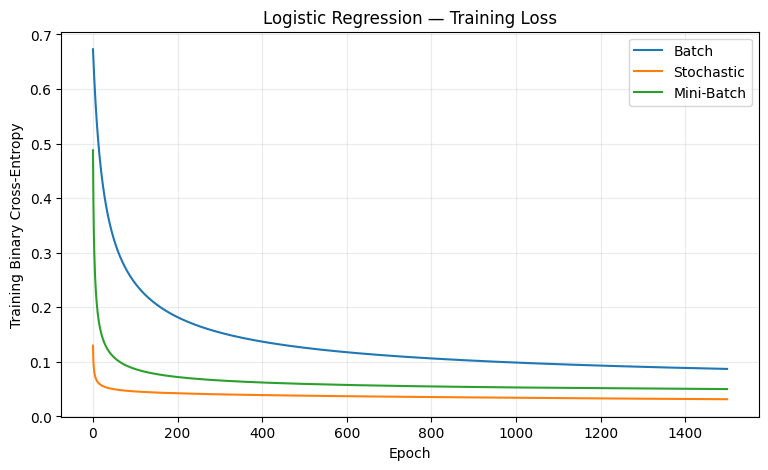

Classification report — best custom model:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



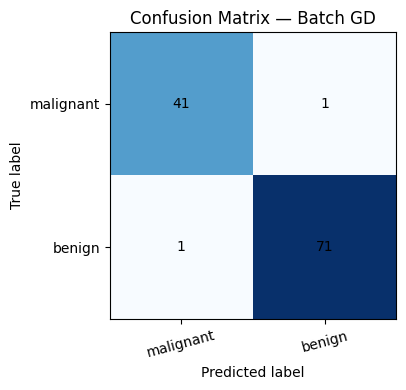

In [11]:
plt.figure(figsize=(9, 5))
for method, model in logistic_models.items():
    plt.plot(model.loss_history, label=method.title())
plt.xlabel("Epoch")
plt.ylabel("Training Binary Cross-Entropy")
plt.title("Logistic Regression — Training Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

best_custom_method = logistic_results_df[
    logistic_results_df["Model"].str.startswith("Custom")
].iloc[0]["Model"].replace("Custom ", "").replace(" GD", "").lower()
best_custom_model = logistic_models[best_custom_method]
best_custom_predictions = best_custom_model.predict(X_test_c)

print("Classification report — best custom model:")
print(classification_report(
    y_test_c, best_custom_predictions,
    target_names=cancer.target_names,
    zero_division=0
))

cm = confusion_matrix(y_test_c, best_custom_predictions)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title(f"Confusion Matrix — {best_custom_method.title()} GD")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], cancer.target_names, rotation=15)
plt.yticks([0, 1], cancer.target_names)
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## Conclusion

This project implements linear and logistic regression optimization methods from scratch and compares them with Scikit-learn baselines.

### Main takeaways
- Batch GD calculates each update using the full training set.
- SGD updates parameters one sample at a time.
- Mini-Batch GD uses a subset of samples per update.
- Feature standardization is important for stable gradient-based logistic regression.
- Test-set metrics provide a fair comparison when the same split is used for all models.

### Improvements over the original notebook
- Fixed mini-batch gradient normalization for the final partial batch.
- Fixed the inconsistent learning-rate variable in logistic regression.
- Passed the selected optimization method into each model instance.
- Used stratified splitting for the classification task.
- Added binary cross-entropy loss tracking and evaluation visualizations.

**Limitations:** the notebook uses fixed hyperparameters and a single train/test split. Cross-validation and systematic hyperparameter tuning would provide a more robust comparison.